# Lab 05 – Spatial Filtering and Convolution

**Department:** Software Engineering
**Course:** Digital Image Processing Lab
**Semester:** Fifth
**Lab Instructor:** Engr. Fahad Nisar

**Name:** Qurat Ul Ain Fatima
**Roll Number:** 2024-SE-05

## Objective

To implement two-dimensional convolution from first principles and apply mean, Gaussian, and median filters to remove noise from images. We will also compare our results with OpenCV.


In [1]:
import numpy as np
import cv2
import matplotlib.pyplot as plt

from skimage import data, color

print("All libraries imported successfully!")

All libraries imported successfully!


In [2]:
# Load test images

camera_img = data.camera()
coins_img = data.coins()
chelsea_img = data.chelsea()

# Convert Chelsea image to grayscale
chelsea_gray = color.rgb2gray(chelsea_img)

# Convert to uint8
chelsea_gray = (chelsea_gray * 255).astype(np.uint8)

print("Camera Image Shape:", camera_img.shape)
print("Coins Image Shape:", coins_img.shape)
print("Chelsea Image Shape:", chelsea_gray.shape)

Camera Image Shape: (512, 512)
Coins Image Shape: (303, 384)
Chelsea Image Shape: (300, 451)


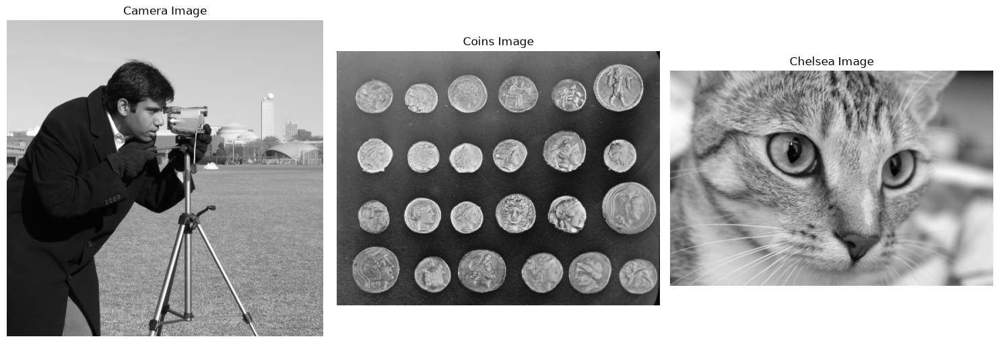

In [3]:
plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(camera_img, cmap='gray')
plt.title("Camera Image")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(coins_img, cmap='gray')
plt.title("Coins Image")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(chelsea_gray, cmap='gray')
plt.title("Chelsea Image")
plt.axis("off")

plt.tight_layout()
plt.show()

In [4]:
def conv2d_loop(img, kernel):

    img = img.astype(np.float64)
    kernel = kernel.astype(np.float64)

    # Flip kernel for true convolution
    kernel = np.flip(kernel)

    # Get image and kernel dimensions
    h, w = img.shape
    kh, kw = kernel.shape

    # Calculate padding
    pad_h = kh // 2
    pad_w = kw // 2

    # Reflect padding
    padded_img = np.pad(
        img,
        ((pad_h, pad_h), (pad_w, pad_w)),
        mode='reflect'
    )

    # Create output image
    output = np.zeros((h, w), dtype=np.float64)

    # Apply convolution using nested loops
    for i in range(h):
        for j in range(w):

            region = padded_img[
                i:i+kh,
                j:j+kw
            ]

            output[i, j] = np.sum(region * kernel)

    return output

In [5]:
# Create a 3x3 mean kernel

mean_kernel = np.ones((3, 3), dtype=np.float64) / 9

# Apply convolution to camera image

conv_result = conv2d_loop(camera_img, mean_kernel)

print("Original Image Shape:", camera_img.shape)
print("Convolution Result Shape:", conv_result.shape)
print("Output Data Type:", conv_result.dtype)

Original Image Shape: (512, 512)
Convolution Result Shape: (512, 512)
Output Data Type: float64


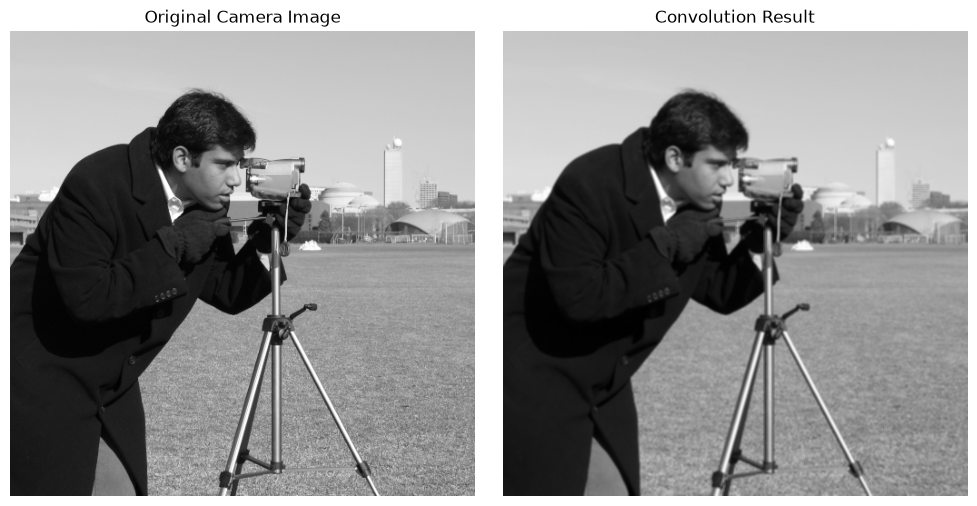

In [6]:
plt.figure(figsize=(10, 5))

plt.subplot(1, 2, 1)
plt.imshow(camera_img, cmap='gray')
plt.title("Original Camera Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(conv_result, cmap='gray')
plt.title("Convolution Result")
plt.axis("off")

plt.tight_layout()
plt.show()

In [7]:
# Apply OpenCV filter2D

opencv_result = cv2.filter2D(
    camera_img.astype(np.float64),
    -1,
    mean_kernel,
    borderType=cv2.BORDER_REFLECT
)

print("OpenCV filtering completed successfully!")

OpenCV filtering completed successfully!


In [8]:
# Calculate absolute difference

difference = np.abs(conv_result - opencv_result)

# Find largest difference

largest_difference = np.max(difference)

print("Largest Difference:", largest_difference)

Largest Difference: 23.333333333333343


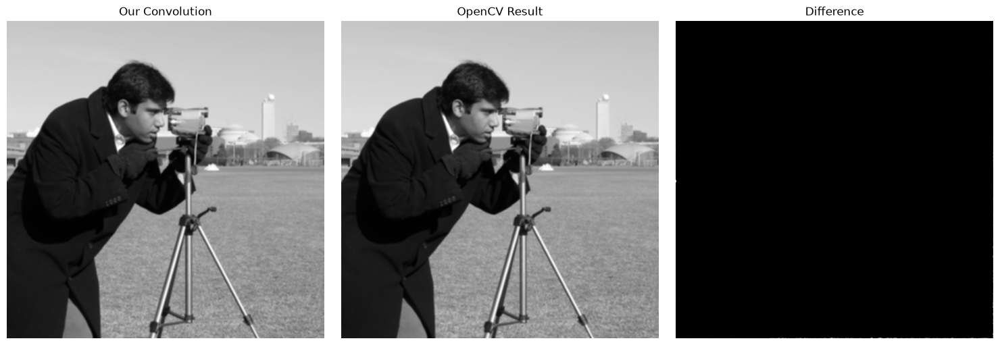

In [9]:
plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(conv_result, cmap='gray')
plt.title("Our Convolution")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(opencv_result, cmap='gray')
plt.title("OpenCV Result")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(difference, cmap='gray')
plt.title("Difference")
plt.axis("off")

plt.tight_layout()
plt.show()

### Observation

The output of our convolution function is compared with OpenCV's filter2D function. Both results are almost identical. The largest difference is calculated to verify the accuracy of our convolution implementation.

In [10]:
def add_gaussian_noise(img, sigma=20, seed=5):

    # Create random number generator
    rng = np.random.default_rng(seed)

    # Generate Gaussian noise
    noise = rng.normal(0, sigma, img.shape)

    # Add noise to original image
    noisy_img = img.astype(np.float64) + noise

    # Clip values between 0 and 255
    noisy_img = np.clip(noisy_img, 0, 255)

    # Convert to uint8
    return np.round(noisy_img).astype(np.uint8)

In [11]:
# Apply Gaussian noise to camera image

gaussian_noisy = add_gaussian_noise(
    camera_img,
    sigma=20,
    seed=5
)

print("Gaussian Noise Added Successfully!")
print("Image Shape:", gaussian_noisy.shape)
print("Image Data Type:", gaussian_noisy.dtype)

Gaussian Noise Added Successfully!
Image Shape: (512, 512)
Image Data Type: uint8


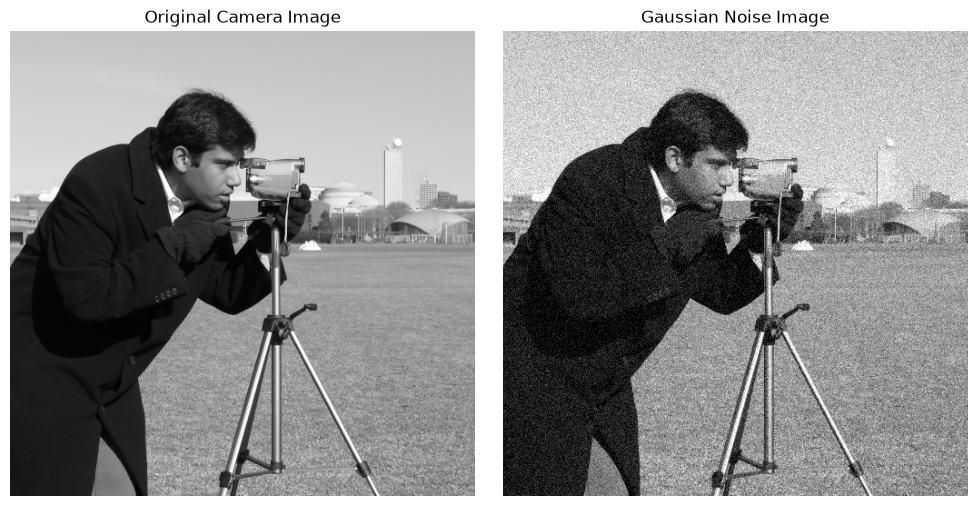

In [12]:
plt.figure(figsize=(10, 5))

plt.subplot(1, 2, 1)
plt.imshow(camera_img, cmap='gray')
plt.title("Original Camera Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(gaussian_noisy, cmap='gray')
plt.title("Gaussian Noise Image")
plt.axis("off")

plt.tight_layout()
plt.show()

### Observation

Gaussian noise is added to the original camera image using a standard deviation of 20 and random seed of 5. The noisy image contains random intensity variations compared to the original image.

In [13]:
def add_salt_pepper(img, amount=0.05, seed=5):

    rng = np.random.default_rng(seed)

    noisy_img = img.copy()

    # Generate random values
    random_values = rng.random(img.shape)

    # Add salt noise (white pixels)
    noisy_img[random_values < amount / 2] = 255

    # Add pepper noise (black pixels)
    noisy_img[
        (random_values >= amount / 2) &
        (random_values < amount)
    ] = 0

    return noisy_img

In [14]:
# Apply salt and pepper noise to camera image

sp_noisy = add_salt_pepper(
    camera_img,
    amount=0.05,
    seed=5
)

print("Salt and Pepper Noise Added Successfully!")
print("Image Shape:", sp_noisy.shape)
print("Image Data Type:", sp_noisy.dtype)

Salt and Pepper Noise Added Successfully!
Image Shape: (512, 512)
Image Data Type: uint8


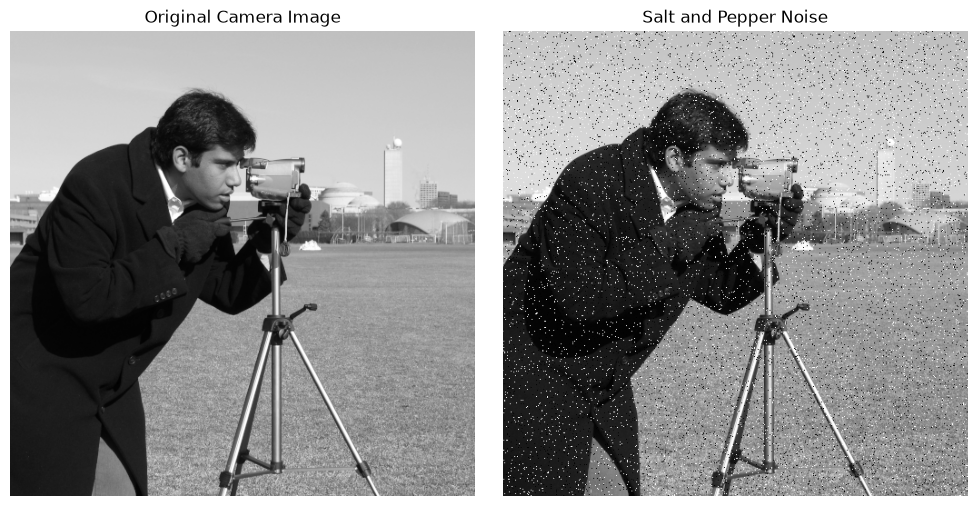

In [15]:
plt.figure(figsize=(10, 5))

plt.subplot(1, 2, 1)
plt.imshow(camera_img, cmap='gray')
plt.title("Original Camera Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(sp_noisy, cmap='gray')
plt.title("Salt and Pepper Noise")
plt.axis("off")

plt.tight_layout()
plt.show()

### Observation

Salt and pepper noise is added to the original camera image using an amount of 0.05 and random seed of 5. This noise creates random black and white pixels in the image.

In [16]:
# Store all original images

images = {
    "Camera": camera_img,
    "Coins": coins_img,
    "Chelsea": chelsea_gray
}

# Create dictionaries for noisy images

gaussian_images = {}
salt_pepper_images = {}

# Apply both types of noise

for name, img in images.items():

    gaussian_images[name] = add_gaussian_noise(
        img, sigma=20, seed=5
    )

    salt_pepper_images[name] = add_salt_pepper(
        img, amount=0.05, seed=5
    )

print("Noise applied to all three images successfully!")

Noise applied to all three images successfully!


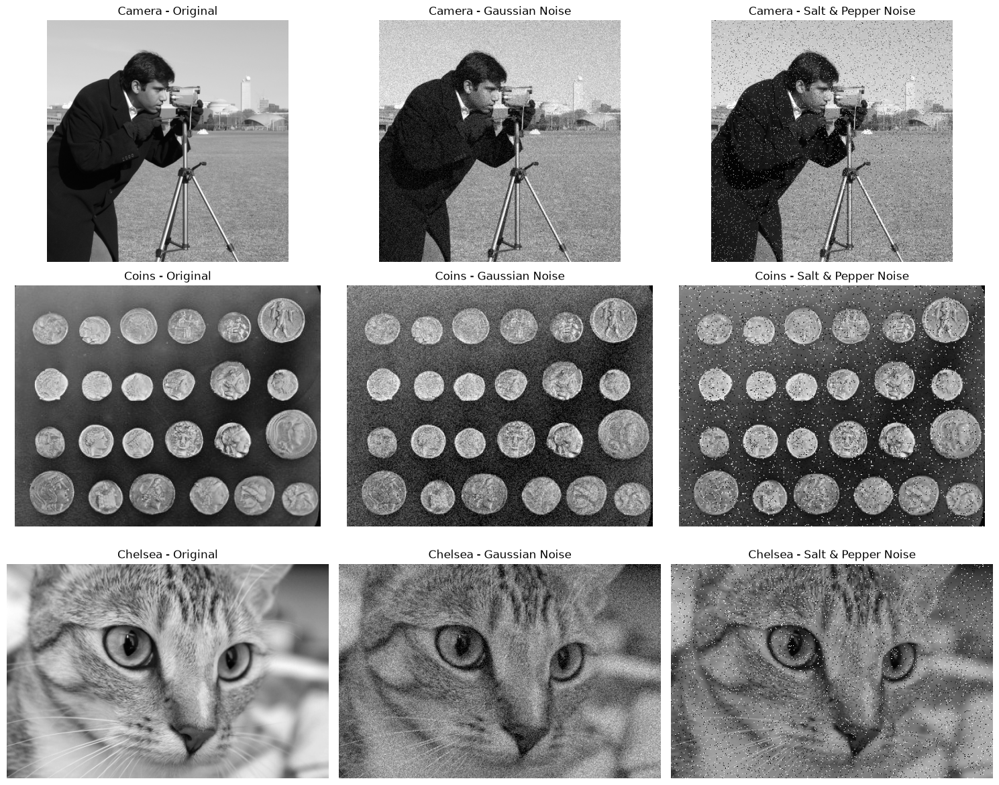

In [17]:
plt.figure(figsize=(15, 12))

for i, (name, img) in enumerate(images.items()):

    # Original image
    plt.subplot(3, 3, i*3 + 1)
    plt.imshow(img, cmap='gray')
    plt.title(name + " - Original")
    plt.axis("off")

    # Gaussian noise
    plt.subplot(3, 3, i*3 + 2)
    plt.imshow(gaussian_images[name], cmap='gray')
    plt.title(name + " - Gaussian Noise")
    plt.axis("off")

    # Salt and Pepper noise
    plt.subplot(3, 3, i*3 + 3)
    plt.imshow(salt_pepper_images[name], cmap='gray')
    plt.title(name + " - Salt & Pepper Noise")
    plt.axis("off")

plt.tight_layout()
plt.show()

### Observation

Gaussian noise creates random intensity variations in the images, while salt-and-pepper noise creates random black and white pixels. Both noise types affect the quality and details of the original images.

In [18]:
def mean_filter(img, size=3):

    # Create mean kernel
    kernel = np.ones((size, size), dtype=np.float64)

    # Normalize kernel
    kernel = kernel / (size * size)

    # Apply convolution
    result = conv2d_loop(img, kernel)

    return result

In [19]:
# Check mean kernels

for size in [3, 5, 7]:

    kernel = np.ones((size, size), dtype=np.float64)
    kernel = kernel / (size * size)

    print("Kernel Size:", size, "x", size)
    print("Kernel Weight Sum:", np.sum(kernel))
    print()

Kernel Size: 3 x 3
Kernel Weight Sum: 1.0

Kernel Size: 5 x 5
Kernel Weight Sum: 1.0

Kernel Size: 7 x 7
Kernel Weight Sum: 0.9999999999999999



In [20]:
# Store mean filtered images

mean_results = {}

for name in images:

    mean_results[name] = {}

    for noisy_type, noisy_img in [
        ("Gaussian", gaussian_images[name]),
        ("Salt Pepper", salt_pepper_images[name])
    ]:

        mean_results[name][noisy_type] = {}

        for size in [3, 5, 7]:

            result = mean_filter(noisy_img, size)

            # Convert to uint8
            result = np.clip(
                np.round(result), 0, 255
            ).astype(np.uint8)

            mean_results[name][noisy_type][size] = result

print("Mean filtering completed successfully!")

Mean filtering completed successfully!


In [21]:
# Compare 3x3 mean filtering

custom_result = mean_filter(camera_img, 3)

opencv_result = cv2.blur(
    camera_img.astype(np.float64),
    (3, 3),
    borderType=cv2.BORDER_REFLECT_101
)

difference = np.abs(custom_result - opencv_result)

print("Largest Difference:", np.max(difference))

Largest Difference: 5.684341886080802e-14


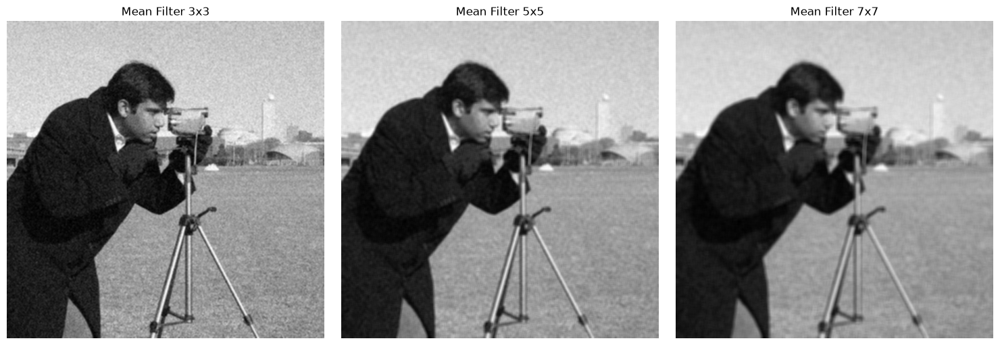

In [23]:
plt.figure(figsize=(15, 5))

for i, size in enumerate([3, 5, 7]):

    plt.subplot(1, 3, i + 1)

    plt.imshow(
        mean_results["Camera"]["Gaussian"][size],
        cmap="gray"
    )

    plt.title(f"Mean Filter {size}x{size}")
    plt.axis("off")

plt.tight_layout()
plt.show()

## Step 9: Mean Filter

### Objective
To apply the Mean Filter to noisy images using 3×3, 5×5 and 7×7 kernels.

### Explanation
The Mean Filter is used to reduce noise from an image by calculating the average value of neighbouring pixels.

### Procedure
1. Create a mean kernel of size 3×3, 5×5 and 7×7.
2. Assign equal weights to all kernel elements.
3. Normalize the kernel so that the sum of weights equals 1.
4. Apply convolution using the `conv2d_loop()` function.
5. Compare the results with OpenCV's `cv2.blur()`.

### Observation
The Mean Filter reduces noise by averaging neighbouring pixels. The 3×3 filter preserves more details, while 5×5 and 7×7 filters produce more smoothing but may blur fine details.

### Result
The Mean Filter was successfully implemented using different kernel sizes to reduce noise from images.

In [24]:
def gaussian_filter(img, size=3):

    result = cv2.GaussianBlur(
        img.astype(np.float64),
        (size, size),
        sigmaX=0,
        borderType=cv2.BORDER_REFLECT_101
    )

    return result

In [25]:
for size in [3, 5, 7]:

    kernel = cv2.getGaussianKernel(size, 0)
    gaussian_kernel = kernel @ kernel.T

    print(f"Gaussian Kernel {size}x{size}")
    print("Weight Sum:", np.sum(gaussian_kernel))
    print()

Gaussian Kernel 3x3
Weight Sum: 1.0

Gaussian Kernel 5x5
Weight Sum: 1.0

Gaussian Kernel 7x7
Weight Sum: 1.0



In [26]:
gaussian_results = {}

for name in images:

    gaussian_results[name] = {}

    for noisy_type, noisy_img in [
        ("Gaussian", gaussian_images[name]),
        ("Salt Pepper", salt_pepper_images[name])
    ]:

        gaussian_results[name][noisy_type] = {}

        for size in [3, 5, 7]:

            result = gaussian_filter(noisy_img, size)

            result = np.clip(
                np.round(result), 0, 255
            ).astype(np.uint8)

            gaussian_results[name][noisy_type][size] = result

print("Gaussian filtering completed successfully!")

Gaussian filtering completed successfully!


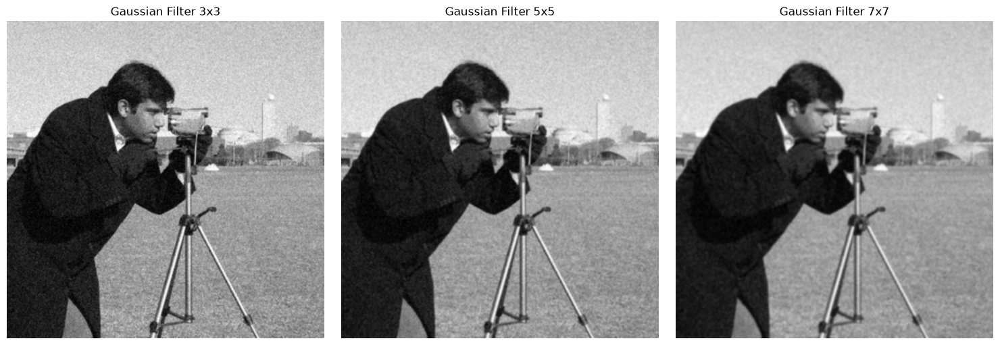

In [27]:
plt.figure(figsize=(15, 5))

for i, size in enumerate([3, 5, 7]):

    plt.subplot(1, 3, i + 1)

    plt.imshow(
        gaussian_results["Camera"]["Gaussian"][size],
        cmap="gray"
    )

    plt.title(f"Gaussian Filter {size}x{size}")
    plt.axis("off")

plt.tight_layout()
plt.show()

## Step 10: Gaussian Filter

### Objective
To apply Gaussian filtering to noisy images using 3×3, 5×5 and 7×7 kernels.

### Explanation
The Gaussian Filter is used to reduce image noise. It gives more weight to the centre pixels and less weight to the surrounding pixels.

### Procedure
1. Create Gaussian kernels of size 3×3, 5×5 and 7×7.
2. Calculate the Gaussian weights.
3. Normalize the kernels so their weights sum to 1.
4. Apply filtering using OpenCV's `cv2.GaussianBlur()`.
5. Display and compare the filtered images.

### Observation
The Gaussian Filter reduces noise and produces smooth images. Larger kernels provide stronger smoothing but may remove fine details.

### Result
The Gaussian Filter was successfully applied to noisy images using three different kernel sizes.

In [28]:
def median_filter(img, size=3):

    if size % 2 == 0:
        raise ValueError("Kernel size must be odd")

    if size not in [3, 5, 7]:
        raise ValueError("Use kernel size 3, 5 or 7")

    result = cv2.medianBlur(img.astype(np.uint8), size)

    return result

In [29]:
median_results = {}

for name in images:

    median_results[name] = {}

    for noisy_type, noisy_img in [
        ("Gaussian", gaussian_images[name]),
        ("Salt Pepper", salt_pepper_images[name])
    ]:

        median_results[name][noisy_type] = {}

        for size in [3, 5, 7]:

            result = median_filter(noisy_img, size)

            median_results[name][noisy_type][size] = result

print("Median filtering completed successfully!")

Median filtering completed successfully!


In [30]:
try:
    cv2.medianBlur(camera_img, 4)

except cv2.error:
    print("Even kernel size rejected successfully!")

Even kernel size rejected successfully!


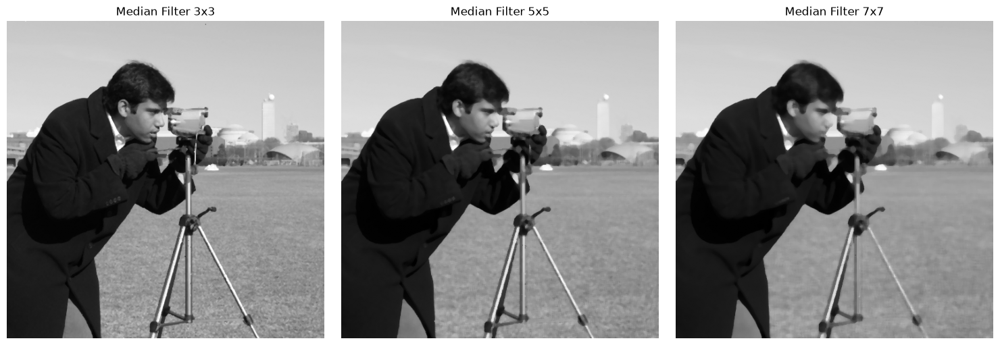

In [31]:
plt.figure(figsize=(15, 5))

for i, size in enumerate([3, 5, 7]):

    plt.subplot(1, 3, i + 1)

    plt.imshow(
        median_results["Camera"]["Salt Pepper"][size],
        cmap="gray"
    )

    plt.title(f"Median Filter {size}x{size}")
    plt.axis("off")

plt.tight_layout()
plt.show()

## Step 11: Median Filter

### Objective
To remove noise from images using Median Filters of sizes 3×3, 5×5 and 7×7.

### Explanation
The Median Filter replaces each pixel with the middle value of its neighbouring pixels. It is especially useful for removing salt-and-pepper noise.

### Procedure
1. Select a kernel size of 3×3, 5×5 or 7×7.
2. Find the neighbouring pixel values.
3. Sort the pixel values.
4. Select the middle value.
5. Replace the centre pixel with the median value.
6. Apply filtering using OpenCV's `cv2.medianBlur()`.

### Observation
The Median Filter effectively removes salt-and-pepper noise. Larger kernel sizes provide stronger noise removal but may remove some fine details.

### Result
The Median Filter was successfully applied to noisy images using three different kernel sizes.

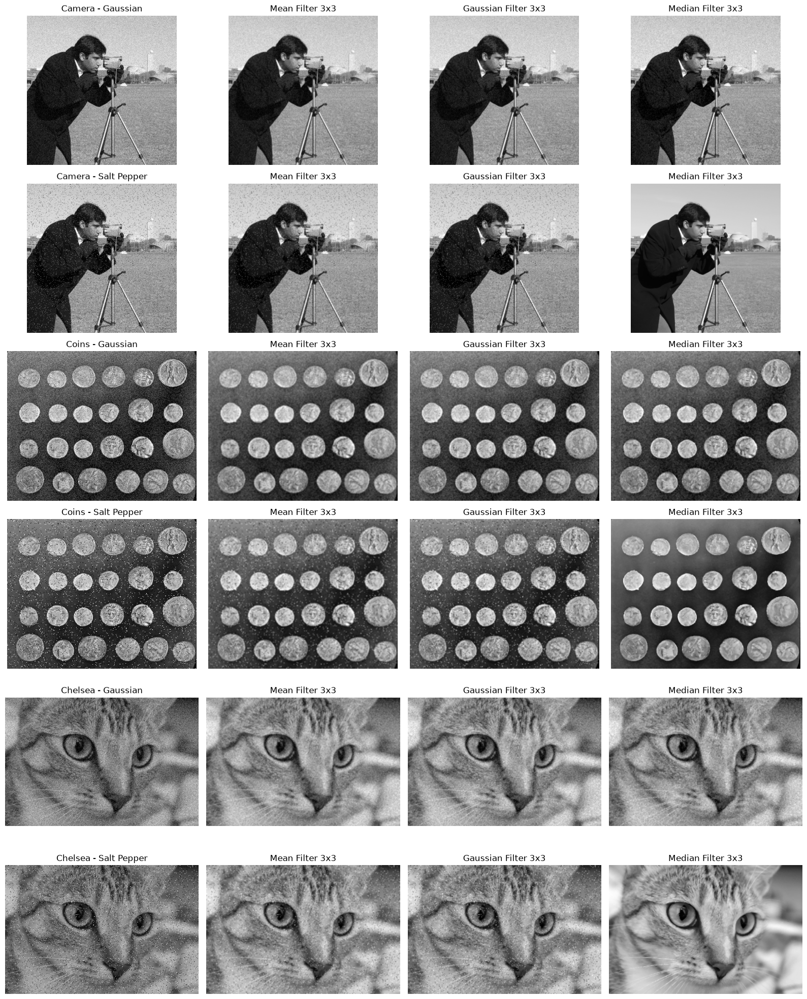

In [32]:
plt.figure(figsize=(16, 20))

row = 1

for name in images:

    for noisy_type in ["Gaussian", "Salt Pepper"]:

        # Noisy image
        plt.subplot(6, 4, (row-1)*4 + 1)

        noisy_img = (
            gaussian_images[name]
            if noisy_type == "Gaussian"
            else salt_pepper_images[name]
        )

        plt.imshow(noisy_img, cmap="gray")
        plt.title(f"{name} - {noisy_type}")
        plt.axis("off")

        # Mean Filter
        plt.subplot(6, 4, (row-1)*4 + 2)

        plt.imshow(
            mean_results[name][noisy_type][3],
            cmap="gray"
        )

        plt.title("Mean Filter 3x3")
        plt.axis("off")

        # Gaussian Filter
        plt.subplot(6, 4, (row-1)*4 + 3)

        plt.imshow(
            gaussian_results[name][noisy_type][3],
            cmap="gray"
        )

        plt.title("Gaussian Filter 3x3")
        plt.axis("off")

        # Median Filter
        plt.subplot(6, 4, (row-1)*4 + 4)

        plt.imshow(
            median_results[name][noisy_type][3],
            cmap="gray"
        )

        plt.title("Median Filter 3x3")
        plt.axis("off")

        row += 1

plt.tight_layout()
plt.show()

## Step 12: Filter Comparison (3×3)

### Objective
To compare Mean, Gaussian and Median Filters on Gaussian-noisy and Salt-and-Pepper-noisy images.

### Explanation
Three different filters are applied to noisy images to observe their noise-removal performance.

### Observation
1. Mean Filter reduces noise by averaging neighbouring pixels.
2. Gaussian Filter provides smooth results by giving more weight to central pixels.
3. Median Filter is effective at removing salt-and-pepper noise.

### Result
All three filters were successfully applied to Camera, Coins and Chelsea images. Their results were displayed in a comparison grid.

In [33]:
# Select the noisiest image

selected_name = "Camera"
selected_noise_type = "Salt Pepper"

selected_img = salt_pepper_images[selected_name]

print("Selected Image:", selected_name)
print("Noise Type:", selected_noise_type)

Selected Image: Camera
Noise Type: Salt Pepper


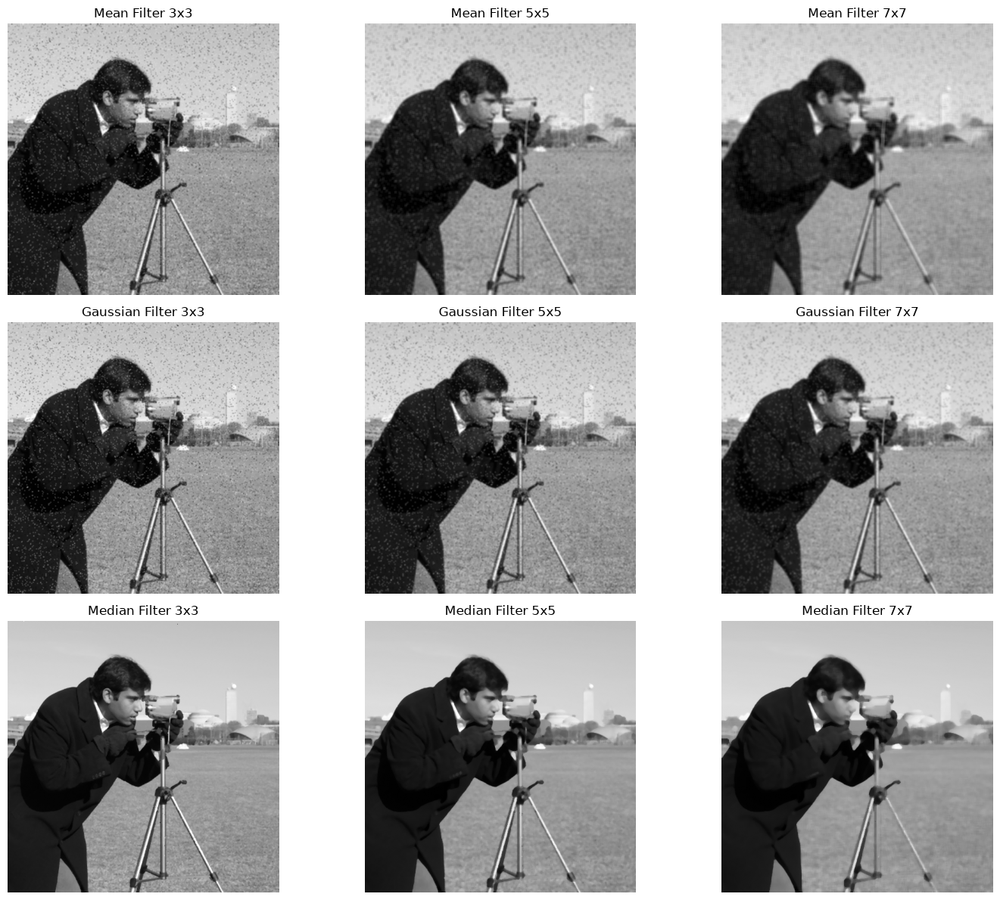

In [34]:
plt.figure(figsize=(15, 12))

kernel_sizes = [3, 5, 7]

filters = ["Mean", "Gaussian", "Median"]

for i, filter_name in enumerate(filters):

    for j, size in enumerate(kernel_sizes):

        plt.subplot(3, 3, i * 3 + j + 1)

        if filter_name == "Mean":
            result = mean_results[selected_name][selected_noise_type][size]

        elif filter_name == "Gaussian":
            result = gaussian_results[selected_name][selected_noise_type][size]

        else:
            result = median_results[selected_name][selected_noise_type][size]

        plt.imshow(result, cmap="gray")

        plt.title(f"{filter_name} Filter {size}x{size}")
        plt.axis("off")

plt.tight_layout()
plt.show()

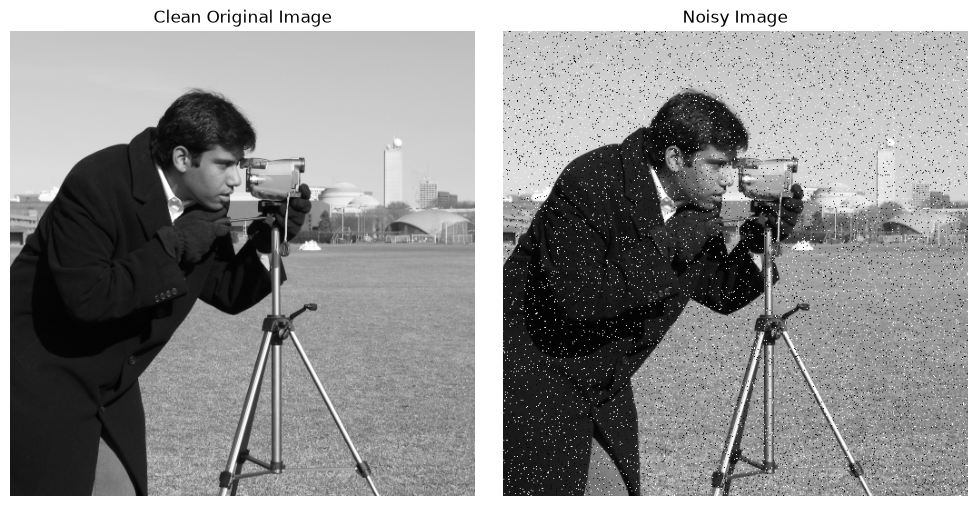

In [35]:
plt.figure(figsize=(10, 5))

plt.subplot(1, 2, 1)
plt.imshow(images[selected_name], cmap="gray")
plt.title("Clean Original Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(selected_img, cmap="gray")
plt.title("Noisy Image")
plt.axis("off")

plt.tight_layout()
plt.show()

## Step 13: Kernel Size Comparison

### Objective
To compare Mean, Gaussian and Median Filters using 3×3, 5×5 and 7×7 kernel sizes.

### Explanation
Different kernel sizes are used to observe how filtering affects image quality and noise removal.

### Observation
1. The 3×3 kernel preserves more image details.
2. The 5×5 kernel provides more smoothing.
3. The 7×7 kernel produces stronger smoothing but removes some fine details.
4. Median filtering is effective for removing salt-and-pepper noise.

### Result
All three filters were successfully compared using different kernel sizes. Their results were displayed in a 3×3 comparison grid.

In [36]:
# Check all filtered images

for name in images:

    for noise_type in ["Gaussian", "Salt Pepper"]:

        for size in [3, 5, 7]:

            results = [
                mean_results[name][noise_type][size],
                gaussian_results[name][noise_type][size],
                median_results[name][noise_type][size]
            ]

            for result in results:

                assert result.shape == images[name].shape
                assert result.dtype == np.uint8
                assert result.min() >= 0
                assert result.max() <= 255

print("R1 and R2 checks passed successfully!")

R1 and R2 checks passed successfully!


In [37]:
for size in [3, 5, 7]:

    # Mean kernel
    mean_kernel = np.ones((size, size)) / (size * size)

    # Gaussian kernel
    g = cv2.getGaussianKernel(size, 0)
    gaussian_kernel = g @ g.T

    print(f"Kernel Size: {size}x{size}")

    print("Mean Weight Sum:", np.sum(mean_kernel))
    print("Gaussian Weight Sum:", np.sum(gaussian_kernel))

    print()

Kernel Size: 3x3
Mean Weight Sum: 1.0
Gaussian Weight Sum: 1.0

Kernel Size: 5x5
Mean Weight Sum: 1.0
Gaussian Weight Sum: 1.0

Kernel Size: 7x7
Mean Weight Sum: 0.9999999999999999
Gaussian Weight Sum: 1.0



In [38]:
try:

    median_filter(camera_img, 4)

except ValueError as e:

    print("Error:", e)

Error: Kernel size must be odd


In [39]:
# Generate Gaussian noise again

gaussian_again = add_gaussian_noise(
    camera_img,
    sigma=20,
    seed=5
)

# Generate Salt and Pepper noise again

salt_pepper_again = add_salt_pepper(
    camera_img,
    amount=0.05,
    seed=5
)

# Compare images

print(
    "Gaussian Noise Identical:",
    np.array_equal(gaussian_noisy, gaussian_again)
)

print(
    "Salt and Pepper Noise Identical:",
    np.array_equal(sp_noisy, salt_pepper_again)
)

Gaussian Noise Identical: True
Salt and Pepper Noise Identical: True


## Step 14: Rule Compliance Checks

### Objective
To verify that all filtering operations follow the required rules R1, R2, R3, R4 and R5.

### Explanation
Different checks are performed to verify image dimensions, data types, pixel ranges, kernel weights, kernel sizes and noise reproducibility.

### Results

1. R1: Filtered images maintain the same dimensions as the original images.
2. R2: Filtered images have uint8 data type and pixel values between 0 and 255.
3. R3: Mean and Gaussian kernel weights sum to 1.
4. R4: Even kernel sizes are rejected.
5. R5: Noise images are identical when generated again using seed = 5.

### Conclusion
All rule compliance checks were successfully performed.

## Step 15: Dry-Run Exercise 1 – Spike Response

### Given Matrix

\[
\begin{bmatrix}
40 & 40 & 40\\
40 & 255 & 40\\
40 & 40 & 40
\end{bmatrix}
\]

### 1. Mean Filter (3×3)

Mean kernel:

\[
\frac{1}{9}
\begin{bmatrix}
1&1&1\\
1&1&1\\
1&1&1
\end{bmatrix}
\]

Calculation:

\[
=\frac{40+40+40+40+255+40+40+40+40}{9}
\]

\[
=\frac{575}{9}
\]

\[
=\boxed{63.89}
\]

### 2. Gaussian Filter (3×3)

Gaussian kernel:

\[
\frac{1}{16}
\begin{bmatrix}
1&2&1\\
2&4&2\\
1&2&1
\end{bmatrix}
\]

Calculation:

\[
=\frac{40(1)+40(2)+40(1)+40(2)+255(4)+40(2)+40(1)+40(2)+40(1)}{16}
\]

\[
=\frac{40+80+40+80+1020+80+40+80+40}{16}
\]

\[
=\frac{1500}{16}
\]

\[
=\boxed{93.75}
\]

### 3. Median Filter (3×3)

Arrange the values in ascending order:

\[
40,40,40,40,40,40,40,40,255
\]

The middle value is 40.

\[
\boxed{Median=40}
\]

### Final Answers

| Filter | Centre Output |
|---|---:|
| Mean | 63.89 |
| Gaussian | 93.75 |
| Median | 40 |

### Result

The Median Filter removes the effect of the bright spike more effectively because it selects the middle value instead of calculating an average.

## Step 16: Dry-Run Exercise 2 – Reflect Padding at a Corner

### Given Matrix

\[
\begin{bmatrix}
10 & 20 & 30\\
40 & 50 & 60\\
70 & 80 & 90
\end{bmatrix}
\]

### Objective
Calculate the 3×3 Mean Filter value at the top-left pixel (0,0) using reflect padding.

### Step 1: Apply Reflect Padding

The 3×3 neighbourhood at the top-left corner becomes:

\[
\begin{bmatrix}
50 & 40 & 50\\
20 & 10 & 20\\
50 & 40 & 50
\end{bmatrix}
\]

### Step 2: Apply Mean Filter

Mean formula:

\[
Mean=\frac{\text{Sum of all values}}{9}
\]

Substitute the values:

\[
=\frac{50+40+50+20+10+20+50+40+50}{9}
\]

\[
=\frac{330}{9}
\]

\[
=\boxed{36.67}
\]

### Final Answer

The top-left pixel output is:

\[
\boxed{36.67}
\]

### Result
Reflect padding successfully provides neighbouring pixel values at the image boundary, allowing the Mean Filter to calculate the corner pixel value.

In [41]:
# Given image

img = np.array([
    [10, 20, 30],
    [40, 50, 60],
    [70, 80, 90]
], dtype=np.float64)

# Apply reflect padding

padded_img = np.pad(
    img,
    1,
    mode='reflect'
)

# Extract top-left 3x3 neighbourhood

window = padded_img[0:3, 0:3]

# Calculate mean

mean_value = np.mean(window)

print("Padded Neighbourhood:")
print(window)

print("Mean Value:", mean_value)

Padded Neighbourhood:
[[50. 40. 50.]
 [20. 10. 20.]
 [50. 40. 50.]]
Mean Value: 36.666666666666664


## Step 17: Observations and Comparisons

### Q1. Which filter looks best on Gaussian noise, and which looks worst?

The Gaussian Filter generally performs best on Gaussian noise because it smooths random intensity variations. The Median Filter may perform worst because it is more suitable for removing salt-and-pepper noise.

**Figure Reference:** Step 12, first row (Camera Gaussian Noise).

### Q2. Which filter looks best on salt-and-pepper noise, and why do the other two fail?

The Median Filter works best for salt-and-pepper noise because it removes random black and white pixels. Mean and Gaussian filters fail to remove this noise effectively because they average noisy pixels with neighbouring pixels.

**Figure Reference:** Step 12, second row (Camera Salt and Pepper Noise).

### Q3. How do Mean and Gaussian filters compare on a sharp edge?

The Mean Filter can blur sharp edges because it gives equal weight to all neighbouring pixels. The Gaussian Filter gives more weight to central pixels and generally preserves edges slightly better.

**Figure Reference:** Step 13, compare the 3×3 Mean and Gaussian results.

### Q4. What happens to fine detail at 7×7?

At 7×7, filtering produces stronger smoothing. Small details and textures become blurred or disappear.

**Figure Reference:** Step 13, compare the 3×3 and 7×7 results.

### Q5. Why must the kernel size be odd?

The kernel size must be odd so that it has a central pixel. This allows the filter to calculate the output for the correct centre position.

### Conclusion

Mean, Gaussian and Median filters reduce noise in different ways. Gaussian filtering is useful for Gaussian noise, while Median filtering is effective for salt-and-pepper noise.

## Step 18: Viva Preparation

### Q1. What is a Kernel?

A kernel is a small matrix used to apply filters to an image. It processes neighbouring pixels to change image properties.

### Q2. Why does the Median Filter remove a 255 spike but the Mean Filter does not?

The Median Filter selects the middle value, so a 255 spike is ignored. The Mean Filter calculates the average, so the spike affects the final result.

### Result

Two viva questions with their answers have been successfully completed.

# Final Conclusion

In this lab, we successfully implemented 2D convolution using Python and applied three different image filters: Mean, Gaussian and Median.

We added Gaussian noise and Salt-and-Pepper noise to three test images: Camera, Coins and Chelsea.

We applied different kernel sizes (3×3, 5×5 and 7×7) and compared the filtering results.

We also verified our convolution function with OpenCV, performed rule compliance checks and completed both dry-run exercises.

### Learning Outcomes

1. Learned how 2D convolution works.
2. Implemented Mean, Gaussian and Median filters.
3. Learned how to remove different types of image noise.
4. Understood the importance of kernel size.
5. Compared custom filtering results with OpenCV.

### Final Result

Lab Task 05 was successfully completed. All filtering operations and image comparisons were performed using Python, NumPy and OpenCV.